# Диагностика 403 кварталов Кореновска — отдельная ячейка

Этот файл подготовлен **без выполнения**. Исходный ноутбук и GeoJSON не менялись.

В VS Code выберите то же ядро `.venv/bin/python`. Прочитайте пояснения и выполните единственную
ячейку кода ниже через **Shift+Enter**. Она сама читает локальные файлы, не требует запуска
`korenovsk_research.ipynb`, не загружает данные, не запускает нарезку и ничего не записывает на диск.
Необходимые диагностические операции выполняются только после вашего запуска этой ячейки.
Показатели качества не являются исследовательскими социальными метриками после контрольной остановки.

## Как понимать результат

- Очень маленькие — менее **100 м²**; маленькие — менее **1000 м² (0.1 га)**.
- Крупные — более **10 га**, дополнительно отмечаются статистические выбросы по площади.
- Узкие — короткая сторона охватывающего повёрнутого прямоугольника <15 м и отношение сторон ≥5,
  **или** индикатор `2 × площадь / периметр` <10 м. Это стартовые учебные пороги, не нормативы.
- Ширина охватывающего прямоугольника — глобальная оценка; для изогнутых или составных полигонов
  она неточна. Низкая компактность может быть вызвана сложной границей, не только узостью.
- Исчезновение при внутреннем отступе 5 м — дополнительный сигнал отсутствия широкого ядра,
  а не точная минимальная ширина. Отступ применяется только к временной копии для проверки.
- Кандидат на артефакт ЖД — маленький или узкий квартал, минимум **50% площади** которого находится
  в пределах **25 м** от сохранённых путей. Это признак для ручного осмотра, не доказательство ошибки.
- `rail_boundary_share` показывает долю периметра в 5 м от железнодорожных линий.
- Сравните таблицы с картой. Узкие земли отвода могут быть реальной транспортной территорией.
  Категории пересекаются — их количества нельзя складывать.
- Пустые, невалидные и неполигональные объекты выводятся отдельно; они **не исправляются** и не
  участвуют в расчётах формы, перекрытий и покрытия. Отчёт об этом явно предупреждает.
- Повторяющиеся геометрии учитываются среди перекрытий. Пары с общей линией границы без общей
  площади не считаются перекрытиями. Допуск пересечения — 0.1 м².
- Пробелы в покрытии сравниваются с городской границей **за вычетом сохранённых водных полигонов**.
  Они не всегда ошибки: нужно проверить источник и контур.

После выполнения пришлите сводную таблицу численности флагов, список кандидатов у ЖД и карту.
Только после этого можно обоснованно выбрать правила объединения или переработки входных линий.
Не возвращайтесь к расчёту городских показателей до проверки кварталов.

## Предлагаемые действия после согласования

1. Сохранить текущие 403 квартала как исходный вариант. Сравнивать будущие сценарии отдельно.
2. Пересмотреть линии-разделители до `preprocess_urban_objects`: в первую очередь станционные
   пути с `service=yard/siding/spur`, параллельные пути, `bridge/tunnel/layer`, строящиеся и полевые дороги.
   Не удалять всю железную дорогу: основной транспортный барьер должен сохраниться.
3. Для станционного узла рассмотреть единый согласованный полигон транспортной территории
   (`buffer` + `dissolve` после осмотра реальной ширины) вместо разрезания каждым путём.
   Не записывать его в исходные данные и не исключать его площадь из баланса молча.
4. Альтернатива повторной нарезке — контролируемое объединение подтверждённых фрагментов с
   соседом по общей границе (`dissolve`). Не объединять через реку, основную ЖД или городскую границу.
   Касание одной точкой недостаточно. Выбор по максимальной общей границе — эвристика, требующая проверки.
5. `postprocess_urban_blocks` в BlocksNet 1.0.0a9 исправляет невалидные геометрии и разделяет
   MultiPolygon; он **не устраняет избыточное дробление**. Классификатор и внутренние функции
   объединения не следует запускать вслепую: нужны категории, здания и проверка барьеров.
6. Для очень крупных кварталов сначала проверить недостающие/незамкнутые разделители и реальные
   функции территории. Крупный парк, промплощадка или поле не обязательно требуют дробления.
7. При новой версии сохранить связь старых и новых `block_id`, сравнить покрытие, число фрагментов,
   узость, ошибки и баланс площади. После изменения кварталов заново готовятся все агрегаты и матрица времени.

Методы: [геометрические операции GeoPandas](https://geopandas.org/en/stable/docs/user_guide/set_operations.html),
[охватывающий повёрнутый прямоугольник Shapely](https://shapely.readthedocs.io/en/stable/reference/shapely.minimum_rotated_rectangle.html).
Рекомендации по BlocksNet основаны на чтении исходников установленной версии **1.0.0a9**.


Железнодорожных объектов, исключённых из диагностики из-за геометрии: 0
Атрибуты железнодорожных линий (число объектов OSM, не отдельных физических путей):


service
spur          32
не указано     6
Name: service, dtype: int64

usage
не указано    22
industrial    11
main           5
Name: usage, dtype: int64

bridge
не указано    37
yes            1
Name: bridge, dtype: int64

layer
не указано    37
1              1
Name: layer, dtype: int64

Система измерений: EPSG:32637 ; длины в метрах, площади в м² и га
Всего кварталов: 403 ; неисправных/пустых/неполигональных: 0
Строк с повторяющимися block_id: 0 ; строк с совпадающими геометриями: 0
Составных MultiPolygon: 0
Порог статистически крупных по Q3+3*IQR, га: 12.431


... (9 outputs left out)

,block_id,area_ha,rectangle_width_m,elongation,width_proxy_m,compactness,rail_distance_m,rail_area_share,rail_boundary_share
297,297,0.005,2.985,11.839,1.436,0.123,0.0,1.0,1.000
292,292,0.018,4.059,14.396,2.968,0.154,0.0,1.0,1.000
355,355,0.019,5.214,10.879,3.227,0.175,0.0,1.0,1.000
310,310,0.040,7.531,14.075,3.747,0.110,0.0,1.0,1.000
305,305,0.049,8.508,13.482,4.230,0.115,0.0,1.0,1.000
322,322,0.125,6.107,48.793,4.189,0.044,0.0,1.0,1.000
357,357,0.127,9.446,31.784,4.225,0.044,0.0,1.0,1.000
303,303,0.153,9.353,29.129,5.576,0.064,0.0,1.0,1.000
354,354,0.172,35.070,7.645,6.098,0.068,0.0,1.0,0.618
306,306,0.190,49.109,6.626,5.574,0.051,0.0,1.0,1.000


Перекрывающихся пар: 0


,block_a,block_b,overlap_m2


Невалидных водных полигонов исключено: 0
Непокрытая территория без известных водных полигонов, га: 0.0
Кварталы за пределами города, га: 0.0
Кварталы внутри исключаемых водных полигонов, га: 0.0
Баланс и перекрытия рассчитаны только по корректным полигонам; исключённые геометрии требуют отдельного разбора


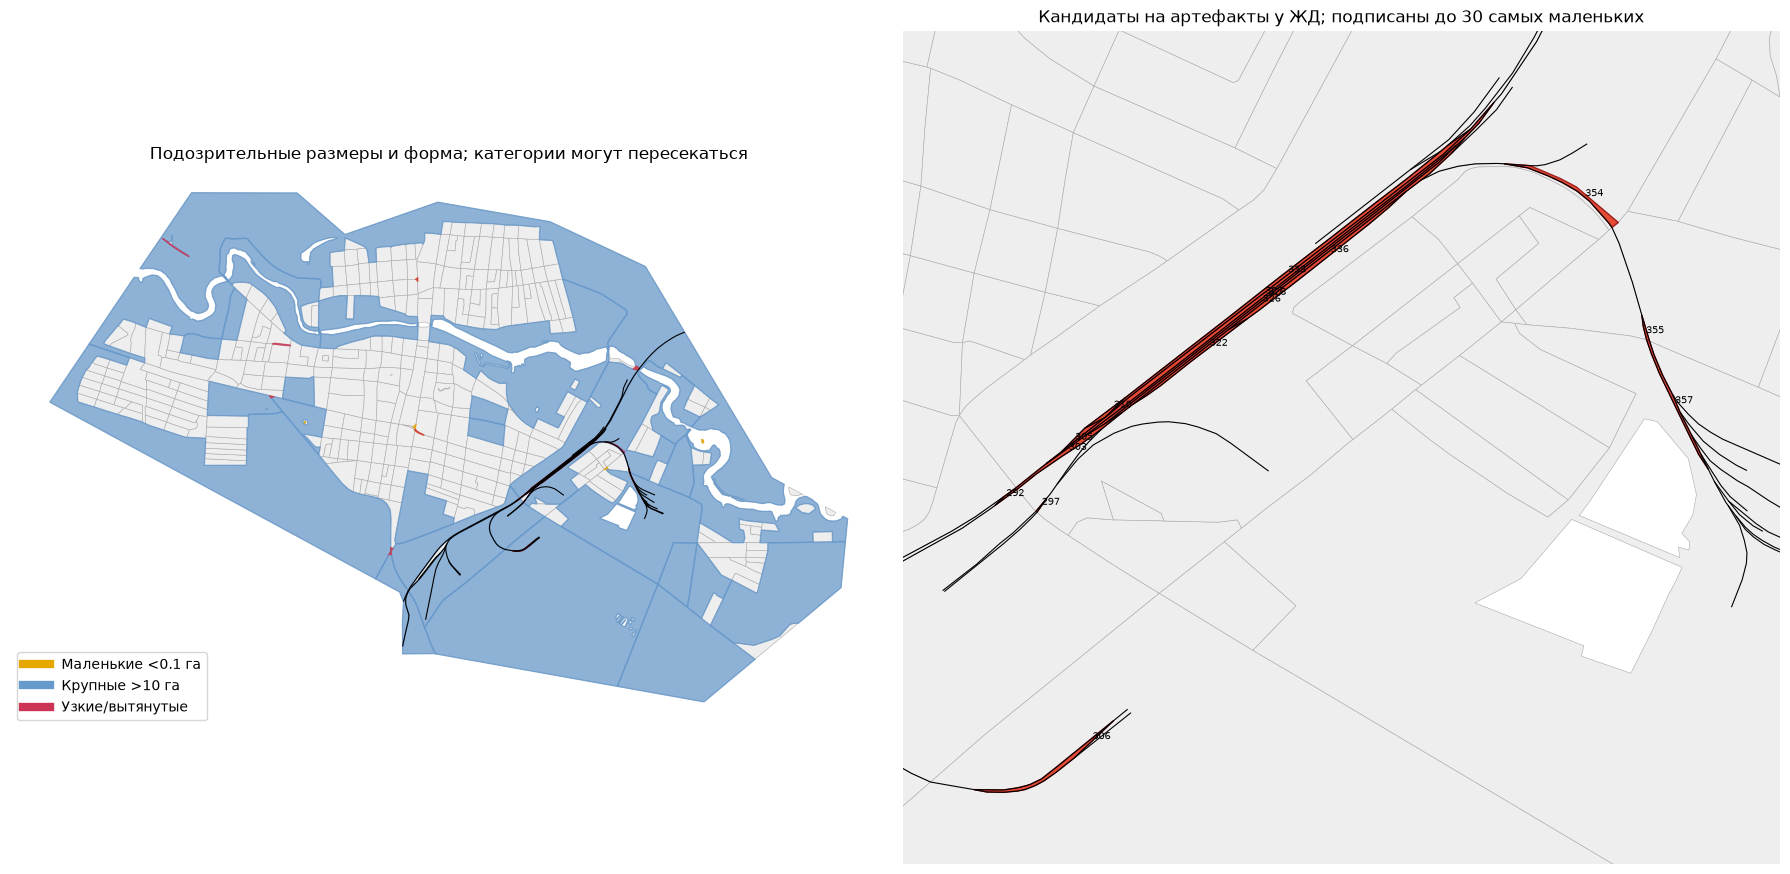

Исходные файлы не изменились. Результаты находятся только в памяти (_diag_good, _diag_overlaps) и выводе ячейки
Пороговые флаги указывают кандидатов на осмотр, а не доказывают ошибку нарезки


In [1]:
# Только чтение локальных файлов и расчёты в памяти. Ничего не загружается и не сохраняется.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.validation import explain_validity
from IPython.display import display

_diag_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "pyproject.toml").exists() and (p / "examples").is_dir()), None)
assert _diag_root is not None, "Откройте папку учебного проекта в VS Code"
_diag_base = _diag_root / "examples" / "data" / "korenovsk"
_diag_paths = {"blocks": _diag_base / "processed/blocks.geojson",
               "railways": _diag_base / "raw/railways.geojson",
               "boundary": _diag_base / "raw/city_boundary.geojson",
               "water": _diag_base / "raw/water.geojson"}
assert _diag_paths["blocks"].exists(), "Не найден processed/blocks.geojson"
_diag_hashes = {k: hashlib.sha256(p.read_bytes()).hexdigest()
                for k, p in _diag_paths.items() if p.exists()}

def _diag_read(path):
    data = json.loads(path.read_text(encoding="utf-8"))
    # Файлы исследования сохранялись в WGS84. Для пустого слоя сохраняем GeoDataFrame.
    if data.get("features"):
        return gpd.GeoDataFrame.from_features(data["features"], crs=4326)
    return gpd.GeoDataFrame(geometry=[], crs=4326)

_diag_original = _diag_read(_diag_paths["blocks"])
assert not _diag_original.empty, "Слой кварталов пуст"
assert "block_id" in _diag_original, "В файле отсутствует block_id"
_diag_crs = _diag_original.estimate_utm_crs()
assert _diag_crs is not None and _diag_crs.is_projected
_diag = _diag_original.to_crs(_diag_crs).copy().reset_index(drop=True)
_diag["geometry_ok"] = (_diag.geometry.notna() & ~_diag.geometry.is_empty
                        & _diag.geometry.is_valid & _diag.geom_type.isin(["Polygon", "MultiPolygon"]))
_diag["validity_reason"] = _diag.geometry.map(lambda g: explain_validity(g) if g is not None else "Нет геометрии")
_diag["multipart"] = _diag.geom_type == "MultiPolygon"
_diag["duplicate_id"] = _diag.block_id.duplicated(keep=False)
_diag["duplicate_geometry"] = False
_diag.loc[_diag.geometry_ok, "duplicate_geometry"] = (
    _diag.loc[_diag.geometry_ok].geometry.normalize().to_wkb().duplicated(keep=False))
_diag_good = _diag.loc[_diag.geometry_ok].copy()
assert len(_diag_good), "Нет корректных полигонов. Сначала разберите таблицу ошибок геометрии"

# Стартовые учебные пороги, не нормативы и не основания для автоматического удаления.
_diag_limits = {"tiny_m2": 100, "small_m2": 1000, "large_m2": 100000,
                "rectangle_width_m": 15, "elongation": 5, "proxy_width_m": 10,
                "rail_buffer_m": 25, "rail_boundary_tolerance_m": 5,
                "rail_area_share": 0.5, "overlap_tolerance_m2": 0.1}
_diag_good["area_m2"] = _diag_good.area
_diag_good["area_ha"] = _diag_good.area / 10000
_diag_good["perimeter_m"] = _diag_good.length
_diag_good["compactness"] = 4 * np.pi * _diag_good.area / _diag_good.length.pow(2)
# Для длинного прямоугольника 2*площадь/периметр примерно равно ширине.
# Это индикатор, а не измерение минимальной ширины сложного полигона.
_diag_good["width_proxy_m"] = 2 * _diag_good.area / _diag_good.length

def _diag_rectangle(geometry):
    rectangle = geometry.minimum_rotated_rectangle
    if rectangle.geom_type != "Polygon":
        return pd.Series([np.nan, np.nan, np.nan])
    coordinates = np.asarray(rectangle.exterior.coords, dtype=float)[:, :2]
    sides = np.linalg.norm(np.diff(coordinates, axis=0), axis=1)
    short, long = float(sides.min()), float(sides.max())
    return pd.Series([short, long, long / short if short > 0 else np.nan])

_diag_good[["rectangle_width_m", "rectangle_length_m", "elongation"]] = (
    _diag_good.geometry.apply(_diag_rectangle))
_diag_good["no_core_after_5m"] = _diag_good.geometry.buffer(-5).is_empty
# Отрицательный буфер только диагностический, результат не подменяет исходную геометрию.
_q1, _q3 = _diag_good.area_m2.quantile([0.25, 0.75])
_diag_outlier_limit = float(_q3 + 3 * (_q3 - _q1))
_diag_good["tiny"] = _diag_good.area_m2 < _diag_limits["tiny_m2"]
_diag_good["small"] = _diag_good.area_m2 < _diag_limits["small_m2"]
_diag_good["large"] = _diag_good.area_m2 > _diag_limits["large_m2"]
_diag_good["area_outlier"] = _diag_good.area_m2 > _diag_outlier_limit
_diag_good["narrow"] = (
    ((_diag_good.rectangle_width_m < _diag_limits["rectangle_width_m"])
     & (_diag_good.elongation >= _diag_limits["elongation"]))
    | (_diag_good.width_proxy_m < _diag_limits["proxy_width_m"]))

# Оцениваем расположение относительно ЖД по уже сохранённым линиям, без сетевых запросов.
_diag_rails = None
if _diag_paths["railways"].exists():
    _diag_rails = _diag_read(_diag_paths["railways"]).to_crs(_diag_crs)
    _rail_ok = (_diag_rails.geometry.notna() & ~_diag_rails.geometry.is_empty
                & _diag_rails.geometry.is_valid
                & _diag_rails.geom_type.isin(["LineString", "MultiLineString"]))
    print("Железнодорожных объектов, исключённых из диагностики из-за геометрии:", int((~_rail_ok).sum()))
    _diag_rails = _diag_rails.loc[_rail_ok].copy()
if _diag_rails is not None and not _diag_rails.empty:
    print("Атрибуты железнодорожных линий (число объектов OSM, не отдельных физических путей):")
    for _field in ("service", "usage", "bridge", "tunnel", "layer"):
        if _field in _diag_rails:
            display(_diag_rails[_field].fillna("не указано").value_counts().rename(_field))
    _rail_union = _diag_rails.geometry.union_all()
    _rail_zone = _rail_union.buffer(_diag_limits["rail_buffer_m"])
    _rail_tolerance = _rail_union.buffer(_diag_limits["rail_boundary_tolerance_m"])
    _diag_good["rail_distance_m"] = _diag_good.distance(_rail_union)
    _diag_good["rail_area_share"] = _diag_good.intersection(_rail_zone).area / _diag_good.area
    _diag_good["rail_boundary_share"] = _diag_good.boundary.intersection(_rail_tolerance).length / _diag_good.length
    _diag_good["near_rail"] = _diag_good.rail_area_share > 0
    _diag_good["possible_rail_artifact"] = (
        (_diag_good.small | _diag_good.narrow)
        & (_diag_good.rail_area_share >= _diag_limits["rail_area_share"]))
else:
    print("ЖД-слой отсутствует/пуст: близость к железной дороге не проверена")
    for _field in ("rail_distance_m", "rail_area_share", "rail_boundary_share"):
        _diag_good[_field] = np.nan
    _diag_good["near_rail"] = pd.Series(pd.NA, index=_diag_good.index, dtype="boolean")
    _diag_good["possible_rail_artifact"] = pd.Series(pd.NA, index=_diag_good.index, dtype="boolean")

# Поиск реальных перекрытий, а не простого соприкосновения границ.
_diag_pairs = []
for _idx, _row in _diag_good.iterrows():
    for _position in _diag_good.sindex.query(_row.geometry, predicate="intersects"):
        _other_idx = _diag_good.index[_position]
        if _other_idx <= _idx:
            continue
        _other = _diag_good.loc[_other_idx]
        _intersection_area = _row.geometry.intersection(_other.geometry).area
        if _intersection_area > _diag_limits["overlap_tolerance_m2"]:
            _diag_pairs.append({"block_a": _row.block_id, "block_b": _other.block_id,
                                "overlap_m2": _intersection_area})
_diag_overlaps = pd.DataFrame(_diag_pairs, columns=["block_a", "block_b", "overlap_m2"])

print("Система измерений:", _diag_crs, "; длины в метрах, площади в м² и га")
print("Всего кварталов:", len(_diag), "; неисправных/пустых/неполигональных:", int((~_diag.geometry_ok).sum()))
print("Строк с повторяющимися block_id:", int(_diag.duplicate_id.sum()),
      "; строк с совпадающими геометриями:", int(_diag.duplicate_geometry.sum()))
print("Составных MultiPolygon:", int(_diag.multipart.sum()))
print("Порог статистически крупных по Q3+3*IQR, га:", round(_diag_outlier_limit / 10000, 3))
if (~_diag.geometry_ok).any():
    display(_diag.loc[~_diag.geometry_ok, ["block_id", "validity_reason"]])
display(pd.Series({label: (int(_diag_good[column].sum()) if _diag_good[column].notna().any() else "Не проверено")
                   for label, column in {
    "Очень маленькие: <100 м²": "tiny", "Маленькие: <0.1 га": "small",
    "Крупные: >10 га": "large", "Статистически крупные": "area_outlier",
    "Узкие/вытянутые по порогам": "narrow", "Исчезают при отступе 5 м": "no_core_after_5m",
    "Частично в 25 м от ЖД": "near_rail", "Кандидаты в артефакты ЖД": "possible_rail_artifact"
}.items()}, name="Число кварталов — категории пересекаются"))
display(_diag_good[["area_ha", "rectangle_width_m", "elongation", "compactness"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3))
_diag_columns = ["block_id", "area_ha", "rectangle_width_m", "elongation", "width_proxy_m",
                 "compactness", "rail_distance_m", "rail_area_share", "rail_boundary_share"]
for _title, _selection in [
    ("20 самых маленьких кварталов", _diag_good.nsmallest(20, "area_m2")),
    ("15 самых крупных кварталов", _diag_good.nlargest(15, "area_m2")),
    ("Узкие/вытянутые: до 30 строк", _diag_good.loc[_diag_good.narrow].sort_values("width_proxy_m").head(30)),
    ("Кандидаты на артефакты ЖД: до 30 строк", _diag_good.loc[
        _diag_good.possible_rail_artifact.fillna(False)].sort_values("area_m2").head(30))]:
    print(_title)
    display(_selection[_diag_columns].round(3))
print("Перекрывающихся пар:", len(_diag_overlaps))
display(_diag_overlaps.head(20))

# Баланс территории: водные полигоны уже исключались при нарезке, их не считаем ошибочными дырами.
if _diag_paths["boundary"].exists():
    _city = _diag_read(_diag_paths["boundary"]).to_crs(_diag_crs)
    if not _city.empty and _city.geometry.is_valid.all():
        _city_union = _city.union_all()
        _expected = _city_union
        _water_skipped = 0
        if _diag_paths["water"].exists():
            _water = _diag_read(_diag_paths["water"]).to_crs(_diag_crs)
            _water_polys = _water.loc[_water.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
            _water_skipped = int((~_water_polys.geometry.is_valid).sum())
            _water_polys = _water_polys.loc[_water_polys.geometry.is_valid]
            if not _water_polys.empty:
                _expected = _city_union.difference(_water_polys.union_all())
        _covered = _diag_good.union_all()
        print("Невалидных водных полигонов исключено:", _water_skipped)
        print("Непокрытая территория без известных водных полигонов, га:",
              round(_expected.difference(_covered).area / 10000, 4))
        print("Кварталы за пределами города, га:", round(_covered.difference(_city_union).area / 10000, 4))
        print("Кварталы внутри исключаемых водных полигонов, га:",
              round(_covered.intersection(_city_union.difference(_expected)).area / 10000, 4))
    else:
        print("Граница отсутствует/невалидна: баланс территории не проверен")
print("Баланс и перекрытия рассчитаны только по корректным полигонам; исключённые геометрии требуют отдельного разбора")

# Статические карты без подложки: нет запросов к картографическим серверам.
_fig, _axes = plt.subplots(1, 2, figsize=(18, 9))
for _ax in _axes:
    _diag_good.plot(ax=_ax, color="#eeeeee", edgecolor="#aaaaaa", linewidth=0.4)
    if _diag_rails is not None and not _diag_rails.empty:
        _diag_rails.plot(ax=_ax, color="black", linewidth=0.8, zorder=5)
    _ax.set_axis_off()
for _mask, _color, _label in [(_diag_good.small, "#e6a700", "Маленькие <0.1 га"),
                              (_diag_good.large, "#6699cc", "Крупные >10 га"),
                              (_diag_good.narrow, "#cc3355", "Узкие/вытянутые")]:
    if _mask.any():
        _diag_good.loc[_mask].plot(ax=_axes[0], color=_color, edgecolor=_color, alpha=0.7)
    _axes[0].plot([], [], color=_color, linewidth=6, label=_label)
_axes[0].legend(loc="lower left")
_axes[0].set_title("Подозрительные размеры и форма; категории могут пересекаться")
_rail_candidates = _diag_good.loc[_diag_good.possible_rail_artifact.fillna(False)]
if not _rail_candidates.empty:
    _rail_candidates.plot(ax=_axes[1], color="#e64b35", edgecolor="#a02020")
    for _, _row in _rail_candidates.nsmallest(30, "area_m2").iterrows():
        _point = _row.geometry.representative_point()
        _axes[1].annotate(str(_row.block_id), (_point.x, _point.y), fontsize=7)
    _xmin, _ymin, _xmax, _ymax = _rail_candidates.total_bounds
    _axes[1].set_xlim(_xmin - 150, _xmax + 150)
    _axes[1].set_ylim(_ymin - 150, _ymax + 150)
_axes[1].set_title("Кандидаты на артефакты у ЖД; подписаны до 30 самых маленьких")
plt.tight_layout()
plt.show()

assert all(hashlib.sha256(_diag_paths[k].read_bytes()).hexdigest() == h for k, h in _diag_hashes.items())
print("Исходные файлы не изменились. Результаты находятся только в памяти (_diag_good, _diag_overlaps) и выводе ячейки")
print("Пороговые флаги указывают кандидатов на осмотр, а не доказывают ошибку нарезки")
